# 00 · Baseline: FinBERT on Twitter Financial News
**AI & Vis UE — Phase I (black box) · AI-aided pair: Dharmik & Sarang**

This notebook produces the shared starting point for Phase I:
1. Load the dataset and FinBERT, and **align the labels by name** (not by index).
2. Run predictions and save a results table (`results_<split>.csv`) with the three softmax scores.
3. Baseline views: confusion matrix, confidence for correct vs. wrong, confidently wrong tweets.
4. First slices (tickers, URLs, numbers, length) to find where errors concentrate.

**Phase I rule:** only inputs, outputs and softmax scores from FinBERT. No attention, gradients or FinBERT embeddings here (those are Phase II).

Runs on free Colab. Use *Runtime → Change runtime type → T4 GPU* (CPU works too, but takes ~20–30 min for 9.5k tweets).
The error analysis continues in `01_neutral_error_analysis.ipynb`.

In [ ]:
!pip -q install transformers datasets scipy

In [1]:
import re, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SPLIT = "train"   # group decision: both pairs use the train split (9.5k tweets, unseen by FinBERT)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cuda


## 1 · Load data and model, align labels

In [2]:
ds = load_dataset("zeroshot/twitter-financial-news-sentiment")
df = ds[SPLIT].to_pandas()
DATA_LABELS = {0: "Bearish", 1: "Bullish", 2: "Neutral"}   # from the dataset card
df["true"] = df["label"].map(DATA_LABELS)
print(df.shape); print(df["true"].value_counts())

README.md:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

sent_train.csv:   0%|          | 0.00/859k [00:00<?, ?B/s]

sent_valid.csv:   0%|          | 0.00/217k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9543 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2388 [00:00<?, ? examples/s]

(9543, 3)
true
Neutral    6178
Bullish    1923
Bearish    1442
Name: count, dtype: int64


In [3]:
tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").to(DEVICE).eval()
id2label = {int(k): v.lower() for k, v in model.config.id2label.items()}
print("FinBERT id2label:", id2label)

# Map by NAME so index order can never cause fake errors
FINBERT_TO_DATA = {"negative": "Bearish", "positive": "Bullish", "neutral": "Neutral"}
assert set(id2label.values()) == set(FINBERT_TO_DATA), "Unexpected FinBERT labels, check config!"

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT id2label: {0: 'positive', 1: 'negative', 2: 'neutral'}


## 2 · Predict and save the results table

In [4]:
@torch.no_grad()
def predict(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i+bs], padding=True, truncation=True, max_length=128, return_tensors="pt").to(DEVICE)
        out.append(torch.softmax(model(**enc).logits, -1).cpu().numpy())
    return np.vstack(out)

probs = predict(df["text"].tolist())
for idx, name in id2label.items():
    df[f"p_{FINBERT_TO_DATA[name].lower()}"] = probs[:, idx]

P = ["p_bearish", "p_bullish", "p_neutral"]
df["pred"] = df[P].idxmax(axis=1).str[2:].str.capitalize()
df["confidence"] = df[P].max(axis=1)
df["correct"] = df["pred"] == df["true"]
df.to_csv(f"results_{SPLIT}.csv", index=False)
df.head()

,text,label,true,p_bullish,p_bearish,p_neutral,pred,confidence,correct
0,$BYND - JPMorgan reels in expectations on Beyo...,0,Bearish,0.189604,0.712802,0.097594,Bearish,0.712802,True
1,$CCL $RCL - Nomura points to bookings weakness...,0,Bearish,0.014297,0.968506,0.017197,Bearish,0.968506,True
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",0,Bearish,0.019847,0.960847,0.019306,Bearish,0.960847,True
3,$ESS: BTIG Research cuts to Neutral https://t....,0,Bearish,0.141393,0.327471,0.531136,Neutral,0.531136,False
4,$FNKO - Funko slides after Piper Jaffray PT cu...,0,Bearish,0.019745,0.935272,0.044984,Bearish,0.935272,True


## 3 · Baseline views
A score table is **not** a Phase I result. These views are only the starting point for finding systematic behavior.

Accuracy: 0.712

              precision    recall  f1-score   support

     Bearish      0.500     0.779     0.609      1442
     Neutral      0.850     0.732     0.786      6178
     Bullish      0.583     0.599     0.591      1923

    accuracy                          0.712      9543
   macro avg      0.644     0.703     0.662      9543
weighted avg      0.743     0.712     0.720      9543



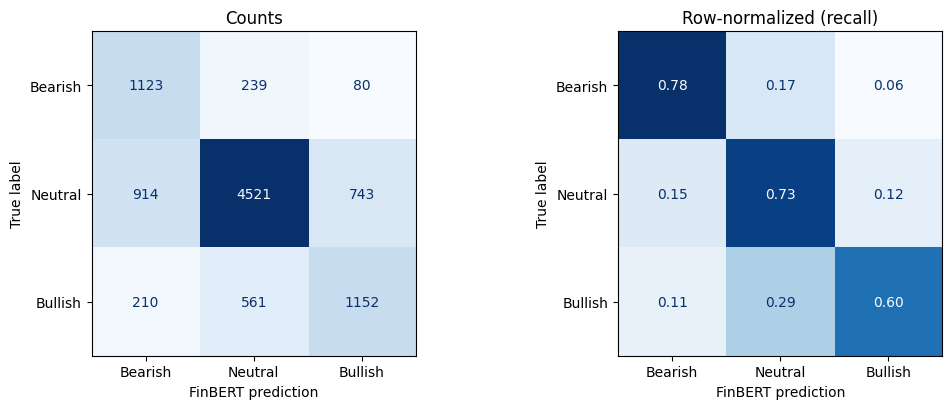

In [5]:
ORDER = ["Bearish", "Neutral", "Bullish"]
print(f"Accuracy: {df['correct'].mean():.3f}\n")
print(classification_report(df["true"], df["pred"], labels=ORDER, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, norm, title in [(axes[0], None, "Counts"), (axes[1], "true", "Row-normalized (recall)")]:
    cm = confusion_matrix(df["true"], df["pred"], labels=ORDER, normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=ORDER).plot(ax=ax, cmap="Blues", colorbar=False,
                                                          values_format=".2f" if norm else "d")
    ax.set_title(title); ax.set_xlabel("FinBERT prediction"); ax.set_ylabel("True label")
plt.tight_layout(); plt.show()

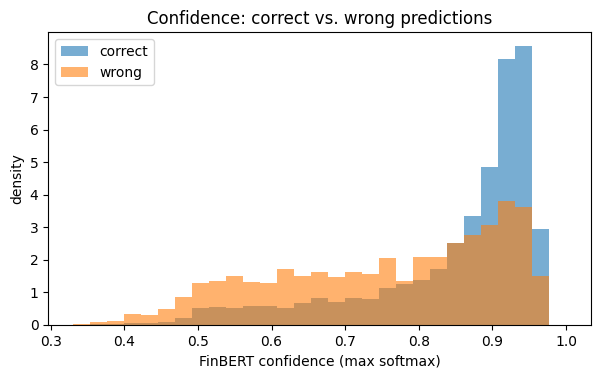

2747 errors, 634 of them with confidence > 0.9


In [6]:
# Is the model confidently wrong?
fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0.33, 1, 30)
ax.hist(df.loc[df.correct, "confidence"], bins=bins, alpha=.6, label="correct", density=True)
ax.hist(df.loc[~df.correct, "confidence"], bins=bins, alpha=.6, label="wrong", density=True)
ax.set_xlabel("FinBERT confidence (max softmax)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Confidence: correct vs. wrong predictions"); plt.show()

wrong = df[~df.correct]
print(f"{len(wrong)} errors, {(wrong.confidence > .9).sum()} of them with confidence > 0.9")

In [7]:
# Most confidently wrong tweets: read these, they are where hypotheses come from
pd.set_option("display.max_colwidth", 140)
wrong.sort_values("confidence", ascending=False)[["text", "true", "pred", "confidence"]].head(25)

,text,true,pred,confidence
433,"Commercial and industrial loans at all commercial banks fall to $2.345 trillion, down $7 billion from a week earlie… https://t.co/IO6JFn...",Neutral,Bearish,0.975982
3623,"Tyson Foods Q1 beef sales fell 8% to $3.84 bln, chicken sales rose 4.5% to $3.29 bln",Neutral,Bearish,0.975574
1786,"PNB Under-Reported Bad Loans By Rs 2,617 Crore In FY19",Neutral,Bearish,0.974025
6902,Stock Market Update: Wholesale inventories decline in December,Bullish,Bearish,0.973877
6426,U.S. trade deficit in goods drops to $63.2 billion in November,Bullish,Bearish,0.973860
6439,12-month rate of core PPI slips to 3-year low of 1.3%,Neutral,Bearish,0.973464
7087,Stocks That Fell to 3-Year Lows in the Week of Dec. 13,Neutral,Bearish,0.973424
4387,"Divestment Will Lead To Loss Of Jobs, Says Concor Employees Union",Neutral,Bearish,0.972330
6519,India's October 1-November 15 sugar output down 64% - industry body,Neutral,Bearish,0.972192
7103,"U.S. stocks end higher Friday, but S&P 500 suffers weekly decline https://t.co/0BZLR3sOoF",Neutral,Bearish,0.971648


## 4 · First slices: where do errors concentrate?

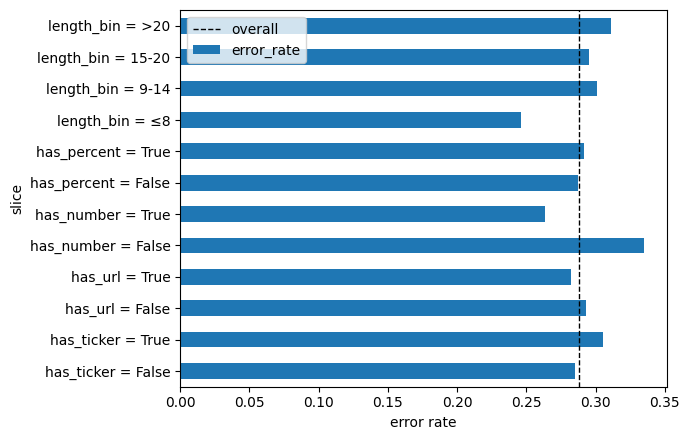

,slice,n,acc,error_rate
0,has_ticker = False,8112,0.715237,0.284763
1,has_ticker = True,1431,0.694619,0.305381
0,has_url = False,5073,0.706880,0.293120
1,has_url = True,4470,0.718121,0.281879
0,has_number = False,3296,0.665352,0.334648
1,has_number = True,6247,0.736834,0.263166
0,has_percent = False,8710,0.712514,0.287486
1,has_percent = True,833,0.708283,0.291717
0,length_bin = ≤8,2138,0.753976,0.246024
1,length_bin = 9-14,4677,0.699166,0.300834


In [8]:
df["has_ticker"]  = df.text.str.contains(r"\$[A-Za-z]{1,5}\b")
df["has_url"]     = df.text.str.contains(r"https?://")
df["has_number"]  = df.text.str.contains(r"\d")
df["has_percent"] = df.text.str.contains(r"%")
df["n_words"]     = df.text.str.split().str.len()
df["length_bin"]  = pd.cut(df.n_words, [0, 8, 14, 20, 100], labels=["≤8", "9-14", "15-20", ">20"])

rows = []
for col in ["has_ticker", "has_url", "has_number", "has_percent", "length_bin"]:
    g = df.groupby(col, observed=True)["correct"].agg(n="size", acc="mean").reset_index()
    g["slice"] = col + " = " + g[col].astype(str)
    rows.append(g[["slice", "n", "acc"]])
slices = pd.concat(rows)
slices["error_rate"] = 1 - slices["acc"]

ax = slices.set_index("slice")["error_rate"].plot.barh(figsize=(7, 4.5))
ax.axvline(1 - df.correct.mean(), ls="--", c="k", lw=1, label="overall")
ax.set_xlabel("error rate"); ax.legend(); plt.tight_layout(); plt.show()
slices

In [9]:
# Error rate per true class within each slice (are errors class-specific?)
pd.crosstab([df.has_ticker, df.has_url], df.true, values=~df.correct, aggfunc="mean").round(3)

true                Bearish  Bullish  Neutral
has_ticker has_url                           
False      False      0.210    0.351    0.286
           True       0.174    0.442    0.274
True       False      0.714    0.525    0.200
           True       0.346    0.467    0.175